# CM2604 Machine Learning – Coursework Part 01
## Telco Customer Churn Prediction: KNN, Logistic Regression and Random Forest

**Student:** Sanithi Dissanayake  |  **Module:** CM2604 Machine Learning (RGU / IIT)  |  **Academic year:** 2026/2027

**Git repository:** `[INSERT PUBLIC GITHUB URL]`

**Contents**
1. Setup and data loading
2. Data cleaning
3. Exploratory data analysis (Task 1)
4. Train/test split and preprocessing
5. Model implementation, hyperparameter tuning and comparison (Task 2)
6. Evaluation plots and interpretation
7. Fairness audit (supports Task 3 – AI ethics)

> **How to run:** `Runtime → Run all`. The dataset is downloaded automatically (the same 7,043-row *Telco Customer Churn* dataset as on Kaggle). If the download fails, upload `Telco-Customer-Churn.csv` to the Colab file panel and re-run.

## 1. Setup and data loading

In [1]:
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42

In [2]:
import os
FILE = "Telco-Customer-Churn.csv"
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
if not os.path.exists(FILE):
    try:
        df_raw = pd.read_csv(URL)
        df_raw.to_csv(FILE, index=False)
    except Exception as e:
        raise SystemExit(f"Download failed ({e}). Upload {FILE} to the Colab file panel and re-run.")
df = pd.read_csv(FILE)
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Data cleaning

In [3]:
# TotalCharges is stored as text; blanks are customers with tenure = 0 (not yet billed)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].replace(" ", np.nan))
print("Missing TotalCharges:", df["TotalCharges"].isna().sum(),
      "| tenure of those rows:", df.loc[df["TotalCharges"].isna(), "tenure"].unique())
print("Duplicate rows (ignoring ID):", df.drop(columns="customerID").duplicated().sum())

df = df.drop(columns="customerID")                      # identifier: no predictive value, identifies individuals
df["Churn"] = (df["Churn"] == "Yes").astype(int)         # target: 1 = churned
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
# 'gender' is kept in the frame for the fairness audit only; it is NOT a model feature (AI ethics)
cat_cols = [c for c in df.columns if c not in num_cols + ["Churn", "gender"]]
print("Numeric:", num_cols); print("Categorical model features:", len(cat_cols))
df.info()

Missing TotalCharges: 11 | tenure of those rows: [0]
Duplicate rows (ignoring ID): 22
Numeric: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical model features: 15
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   str    
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 

In [4]:
df[num_cols].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7032.00
mean,32.37,64.76,2283.30
std,24.56,30.09,2266.77
min,0.00,18.25,18.80
25%,9.00,35.50,401.45
50%,29.00,70.35,1397.48
75%,55.00,89.85,3794.74
max,72.00,118.75,8684.80


## 3. Exploratory data analysis (Task 1)

### 3.1 Class distribution

Churn
0    0.7346
1    0.2654
Name: proportion, dtype: float64


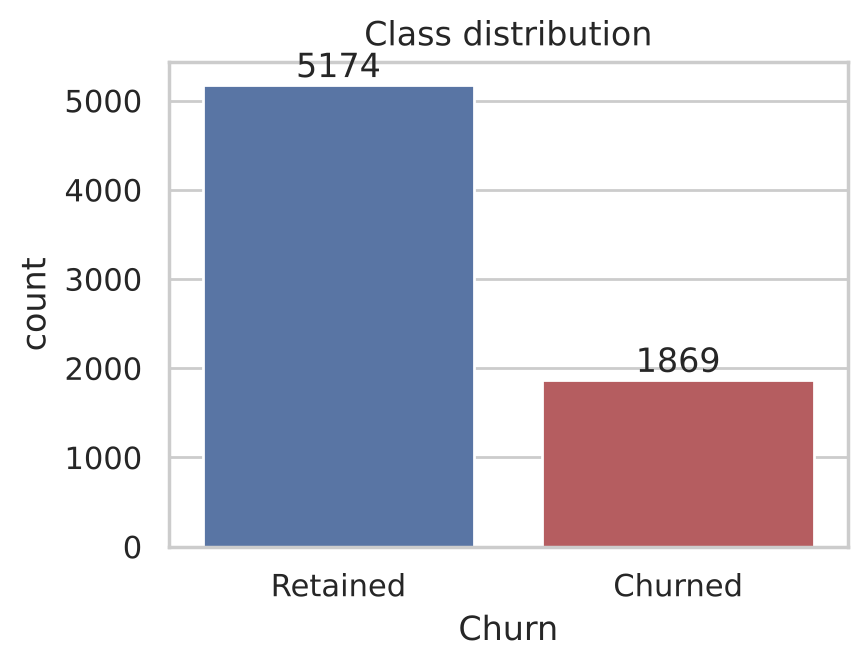

In [5]:
print(df["Churn"].value_counts(normalize=True).round(4))
fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.countplot(x="Churn", data=df, ax=ax, palette=["#4C72B0", "#C44E52"])
ax.set_xticklabels(["Retained", "Churned"]); ax.set_title("Class distribution")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom")
plt.tight_layout(); plt.show()

**Insight:** only 26.5% of customers churned. A model predicting “no churn” for everyone would score 73.5% accuracy, so accuracy alone is misleading – F1, recall and ROC-AUC are used.

### 3.2 Churn rate by key categorical features

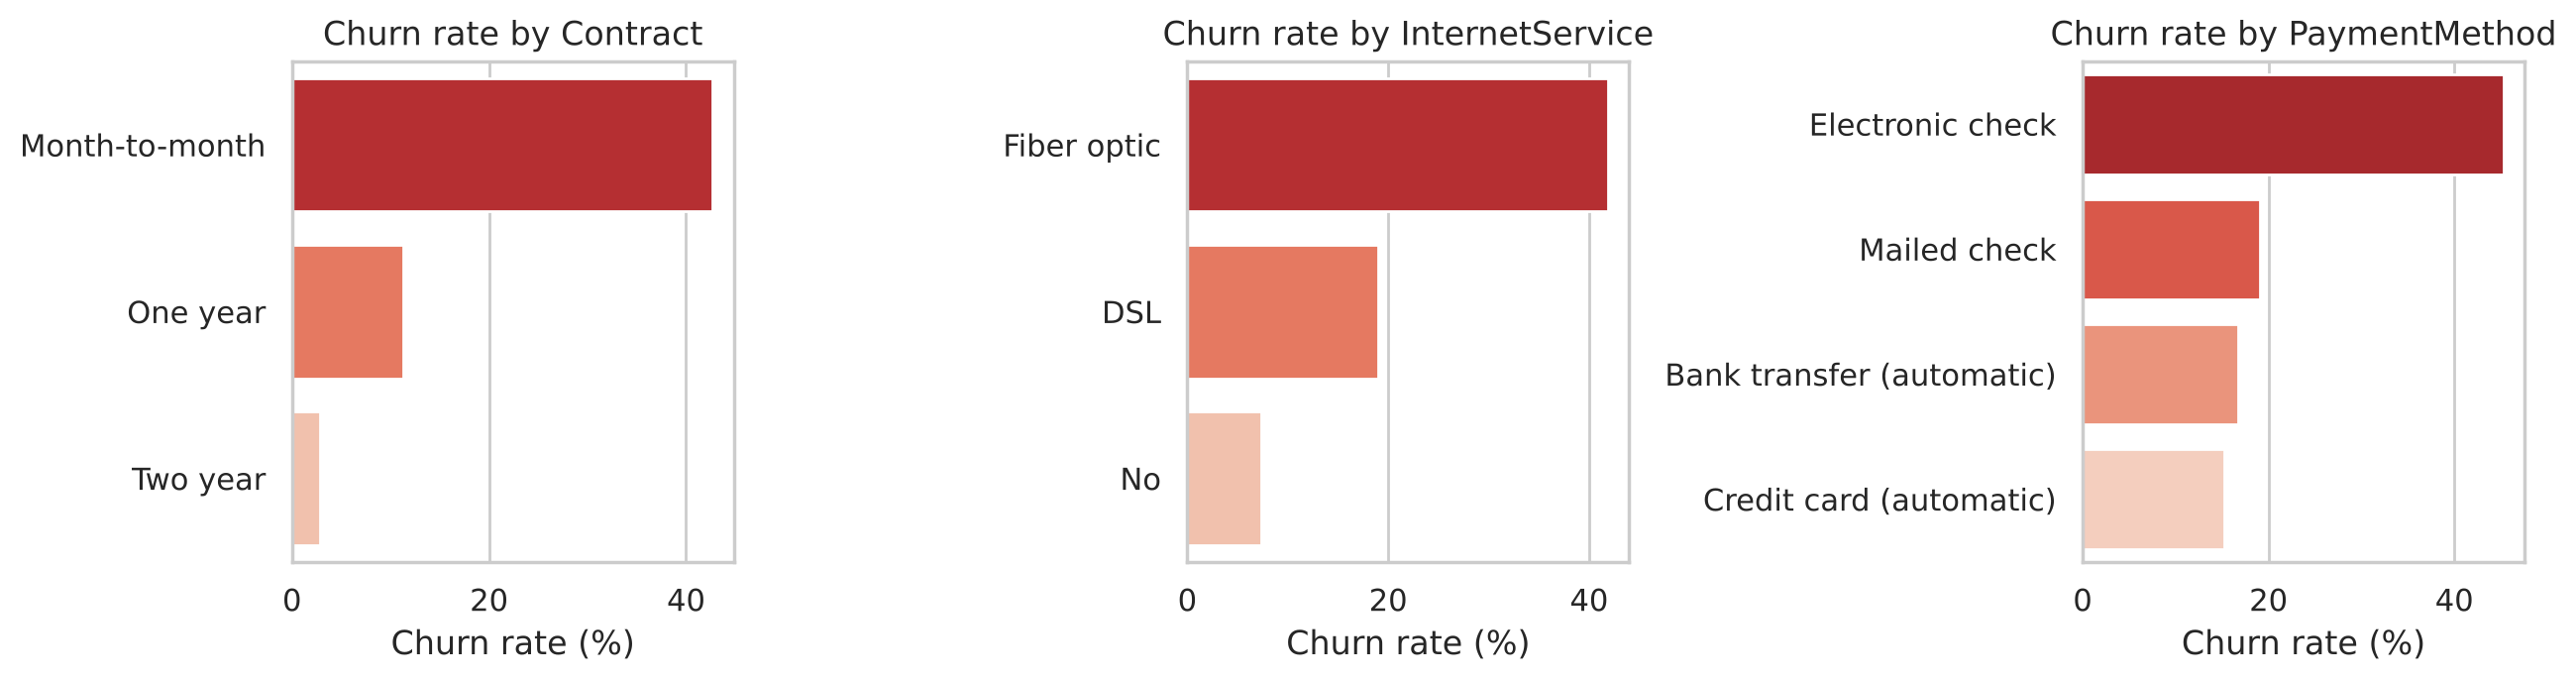

{'Month-to-month': 42.7, 'One year': 11.3, 'Two year': 2.8}
{'DSL': 19.0, 'Fiber optic': 41.9, 'No': 7.4}
{'Bank transfer (automatic)': 16.7, 'Credit card (automatic)': 15.2, 'Electronic check': 45.3, 'Mailed check': 19.1}


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, c in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    r = df.groupby(c)["Churn"].mean().sort_values(ascending=False) * 100
    sns.barplot(x=r.values, y=r.index, ax=ax, palette="Reds_r")
    ax.set_xlabel("Churn rate (%)"); ax.set_ylabel(""); ax.set_title(f"Churn rate by {c}")
plt.tight_layout(); plt.show()
for c in ["Contract", "InternetService", "PaymentMethod"]:
    print((df.groupby(c)["Churn"].mean() * 100).round(1).to_dict())

**Insight:** month-to-month contracts (42.7%), fibre-optic internet (41.9%) and electronic-check payment (45.3%) have much higher churn; two-year contracts churn at only 2.8%.

### 3.3 Numeric features

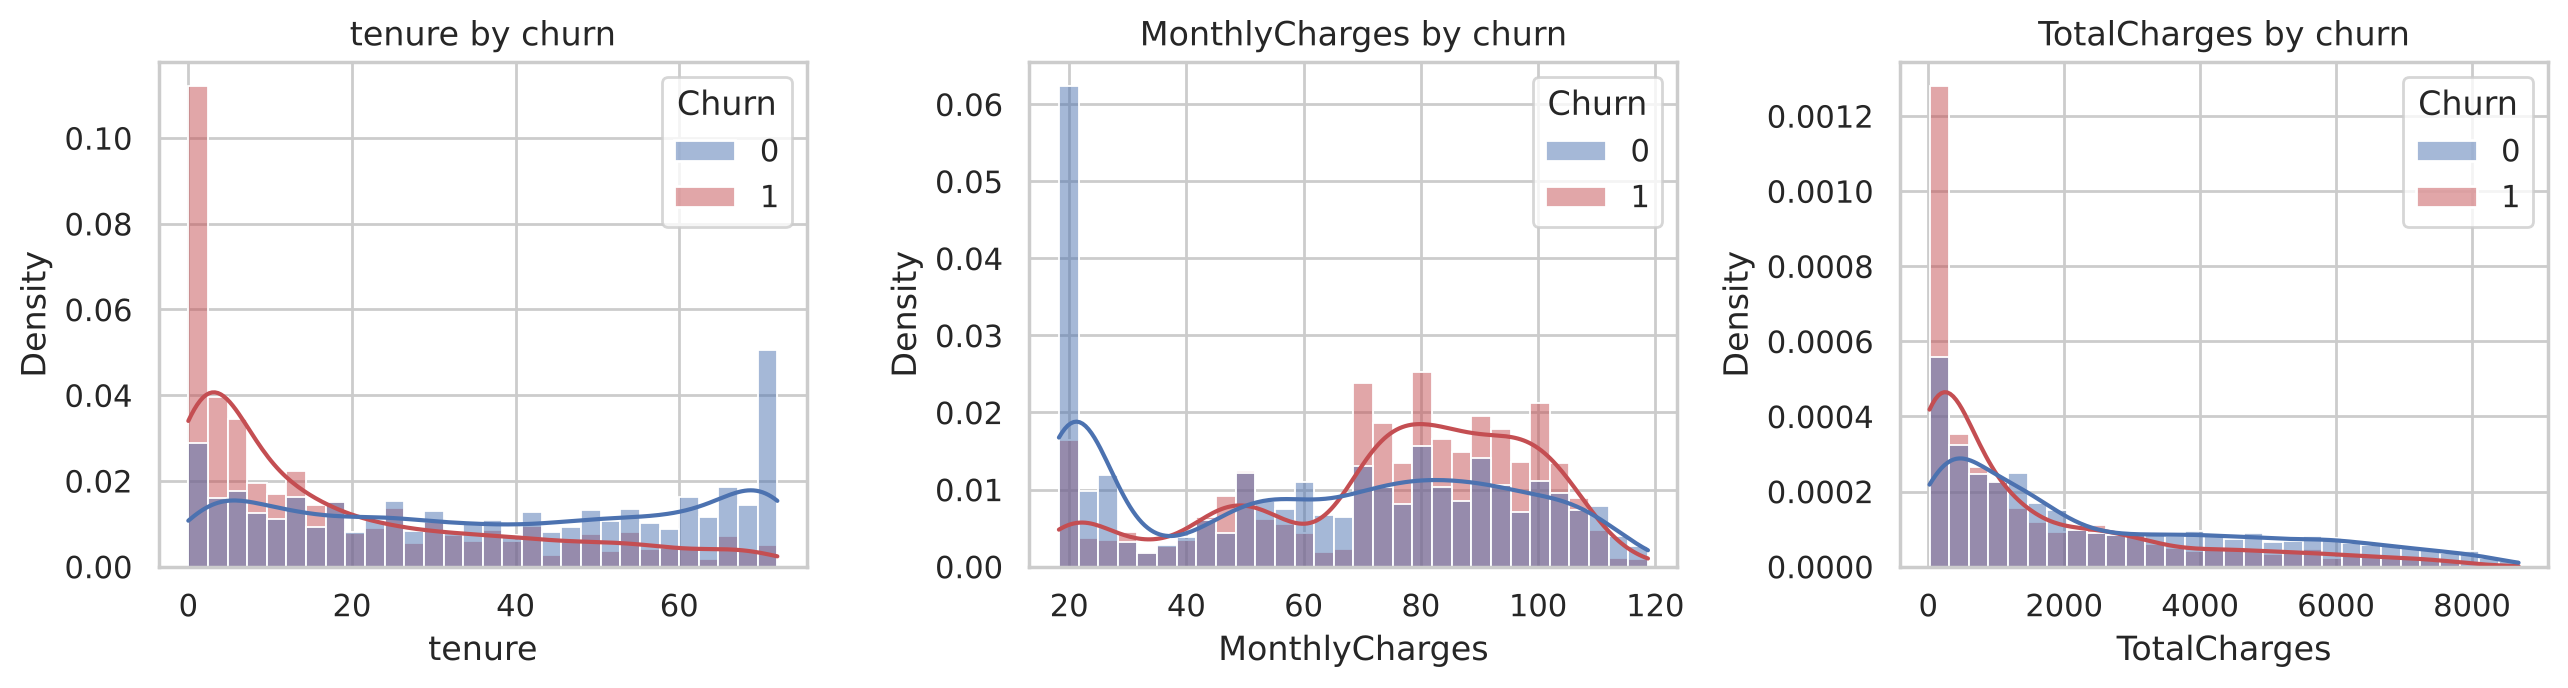

Median tenure by churn: {0: 38.0, 1: 10.0}
Median monthly charge by churn: {0: 64.43, 1: 79.65}


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, c in zip(axes, num_cols):
    sns.histplot(data=df, x=c, hue="Churn", bins=30, kde=True, ax=ax, stat="density",
                 common_norm=False, palette=["#4C72B0", "#C44E52"])
    ax.set_title(f"{c} by churn")
plt.tight_layout(); plt.show()
print("Median tenure by churn:", df.groupby("Churn")["tenure"].median().to_dict())
print("Median monthly charge by churn:", df.groupby("Churn")["MonthlyCharges"].median().round(2).to_dict())

**Insight:** churners have a median tenure of 10 months (vs 38) and pay more per month (≈79.65 vs 64.43). Risk is concentrated early in the customer lifetime.

### 3.4 Correlation

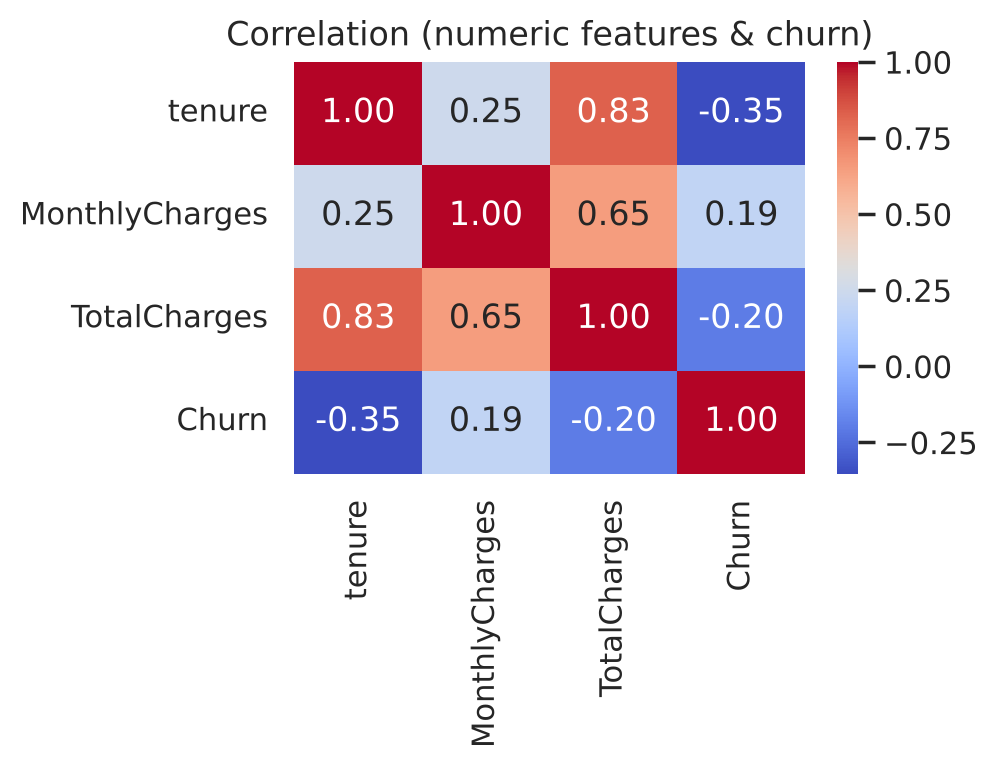

In [8]:
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(df[num_cols + ["Churn"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax)
ax.set_title("Correlation (numeric features & churn)"); plt.tight_layout(); plt.show()

**Insight:** tenure is negatively correlated with churn (r = −0.35); `TotalCharges` is strongly correlated with tenure (r ≈ 0.83), so multicollinearity can distort Logistic Regression coefficients.

### 3.5 Other factors

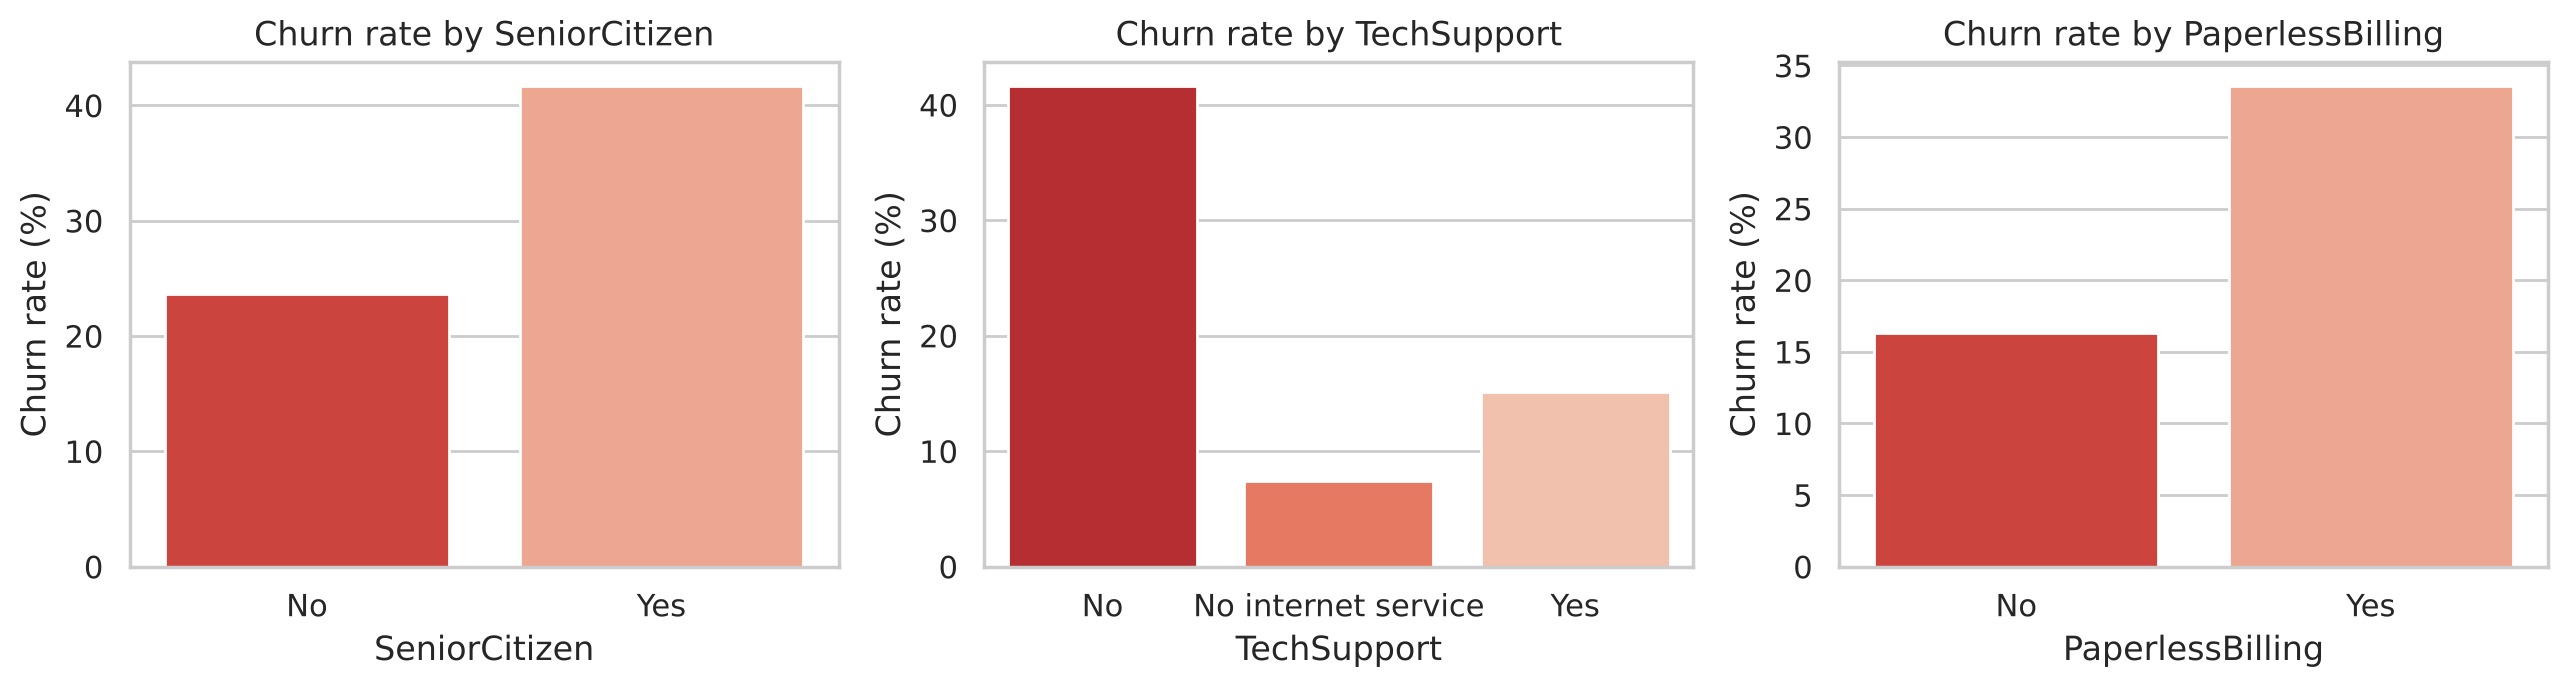

By gender (%): {'Female': 26.9, 'Male': 26.2}


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, c in zip(axes, ["SeniorCitizen", "TechSupport", "PaperlessBilling"]):
    r = df.groupby(c)["Churn"].mean() * 100
    sns.barplot(x=r.index, y=r.values, ax=ax, palette="Reds_r")
    ax.set_ylabel("Churn rate (%)"); ax.set_title(f"Churn rate by {c}")
plt.tight_layout(); plt.show()
print("By gender (%):", (df.groupby("gender")["Churn"].mean() * 100).round(1).to_dict())

**Insight:** senior citizens (41.7% vs 23.6%) and customers without tech support (41.6% vs 15.2%) churn more. **Gender shows no meaningful difference (26.9% vs 26.2%)**, so it is excluded from the models.

## 4. Train/test split and preprocessing
* Stratified 80/20 split **before** any fitting (prevents data leakage).
* Numeric: median imputation (+ standardisation for KNN and Logistic Regression; Random Forest is scale-invariant).
* Categorical: one-hot encoding (binary variables as one column, unseen categories ignored).
* Imbalance: `class_weight="balanced"` for Logistic Regression and Random Forest (KNN has no such option).
* Preprocessing is inside each `Pipeline`, so it is re-fitted within every cross-validation fold.

In [10]:
X, y = df.drop(columns="Churn"), df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate  train: %.3f  test: %.3f" % (y_train.mean(), y_test.mean()))

def preprocessor(scale=True):
    num = [("imp", SimpleImputer(strategy="median"))] + ([("sc", StandardScaler())] if scale else [])
    return ColumnTransformer([
        ("num", Pipeline(num), num_cols),
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_cols)])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

Train: (5634, 19) | Test: (1409, 19)
Churn rate  train: 0.265  test: 0.265


## 5. Model implementation, tuning and comparison (Task 2)
Two experimental settings per model:
* **Setting A – Baseline:** library-default hyperparameters.
* **Setting B – Tuned:** `GridSearchCV`, stratified 5-fold CV on the training set, optimising **ROC-AUC**.

The test set is used **once** per model for the final evaluation.

In [11]:
models = {
    "KNN": (Pipeline([("prep", preprocessor(True)), ("clf", KNeighborsClassifier())]),
            {"clf__n_neighbors": [3, 5, 7, 11, 15, 21, 31],
             "clf__weights": ["uniform", "distance"],
             "clf__p": [1, 2]}),
    "Logistic Regression": (Pipeline([("prep", preprocessor(True)),
                                      ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", solver="liblinear"))]),
                            {"clf__C": [0.001, 0.01, 0.1, 1, 10, 100],
                             "clf__penalty": ["l1", "l2"]}),
    "Random Forest": (Pipeline([("prep", preprocessor(False)),
                                ("clf", RandomForestClassifier(random_state=SEED, class_weight="balanced", n_jobs=-1))]),
                      {"clf__n_estimators": [200],
                       "clf__max_depth": [6, 10, None],
                       "clf__min_samples_leaf": [1, 5, 10],
                       "clf__max_features": ["sqrt"]}),
}

def evaluate(model, name, setting):
    p = model.predict(X_test); s = model.predict_proba(X_test)[:, 1]
    return {"Model": name, "Setting": setting, "Accuracy": accuracy_score(y_test, p),
            "Precision": precision_score(y_test, p), "Recall": recall_score(y_test, p),
            "F1": f1_score(y_test, p), "ROC-AUC": roc_auc_score(y_test, s)}, p, s

rows, tuned_models, best_params, preds = [], {}, {}, {}

def run_model(name):
    pipe, grid = models[name]
    # Setting A: baseline
    base = pipe.fit(X_train, y_train)
    r, _, _ = evaluate(base, name, "Baseline")
    r["CV ROC-AUC"] = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="roc_auc").mean()
    rows.append(r)
    # Setting B: tuned
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="roc_auc", n_jobs=-1, refit=True).fit(X_train, y_train)
    r, p, s = evaluate(gs.best_estimator_, name, "Tuned")
    r["CV ROC-AUC"] = gs.best_score_
    rows.append(r)
    tuned_models[name] = gs.best_estimator_; best_params[name] = gs.best_params_; preds[name] = (p, s)
    print(f"{name}\n  best params : {gs.best_params_}\n  best CV AUC : {gs.best_score_:.4f}")

### 5.1 K-Nearest Neighbours

In [12]:
run_model("KNN")

KNN
  best params : {'clf__n_neighbors': 31, 'clf__p': 2, 'clf__weights': 'uniform'}
  best CV AUC : 0.8339


### 5.2 Logistic Regression

In [13]:
run_model("Logistic Regression")

Logistic Regression
  best params : {'clf__C': 10, 'clf__penalty': 'l2'}
  best CV AUC : 0.8463


### 5.3 Random Forest

In [14]:
run_model("Random Forest")

Random Forest
  best params : {'clf__max_depth': 10, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 10, 'clf__n_estimators': 200}
  best CV AUC : 0.8475


### 5.4 Results – both experimental settings

In [15]:
results = pd.DataFrame(rows).round(4)
results.style.format(precision=3).background_gradient(subset=["F1", "ROC-AUC"], cmap="Greens")

,Model,Setting,Accuracy,Precision,Recall,F1,ROC-AUC,CV ROC-AUC
0,KNN,Baseline,0.758,0.546,0.521,0.533,0.778,0.779
1,KNN,Tuned,0.781,0.589,0.575,0.582,0.826,0.834
2,Logistic Regression,Baseline,0.737,0.503,0.783,0.613,0.842,0.846
3,Logistic Regression,Tuned,0.738,0.504,0.783,0.614,0.841,0.846
4,Random Forest,Baseline,0.763,0.546,0.628,0.585,0.820,0.821
5,Random Forest,Tuned,0.757,0.528,0.797,0.635,0.845,0.848


**Reading the table**
* Tuning helped KNN most (larger *k* smooths the decision boundary); Logistic Regression barely changed (defaults were near-optimal); Random Forest improved markedly (limiting depth / leaf size reduces overfitting).
* Tuned Random Forest has the best **F1, recall and ROC-AUC**; Logistic Regression is within ≈0.004 AUC (within CV noise) and is more interpretable.
* KNN has the highest accuracy but the weakest recall – accuracy is misleading on imbalanced data.

## 6. Evaluation plots and interpretation

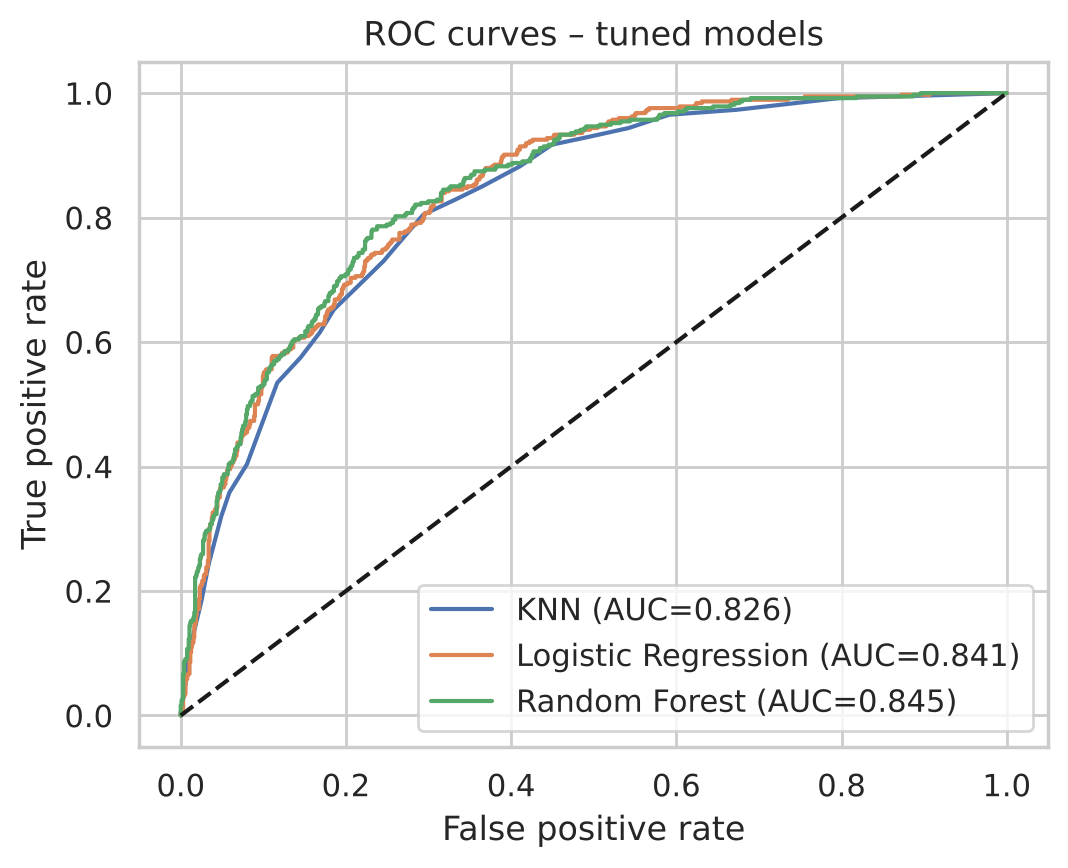

In [16]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
for name, (_, s) in preds.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, s):.3f})")
ax.plot([0, 1], [0, 1], "k--"); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curves – tuned models"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

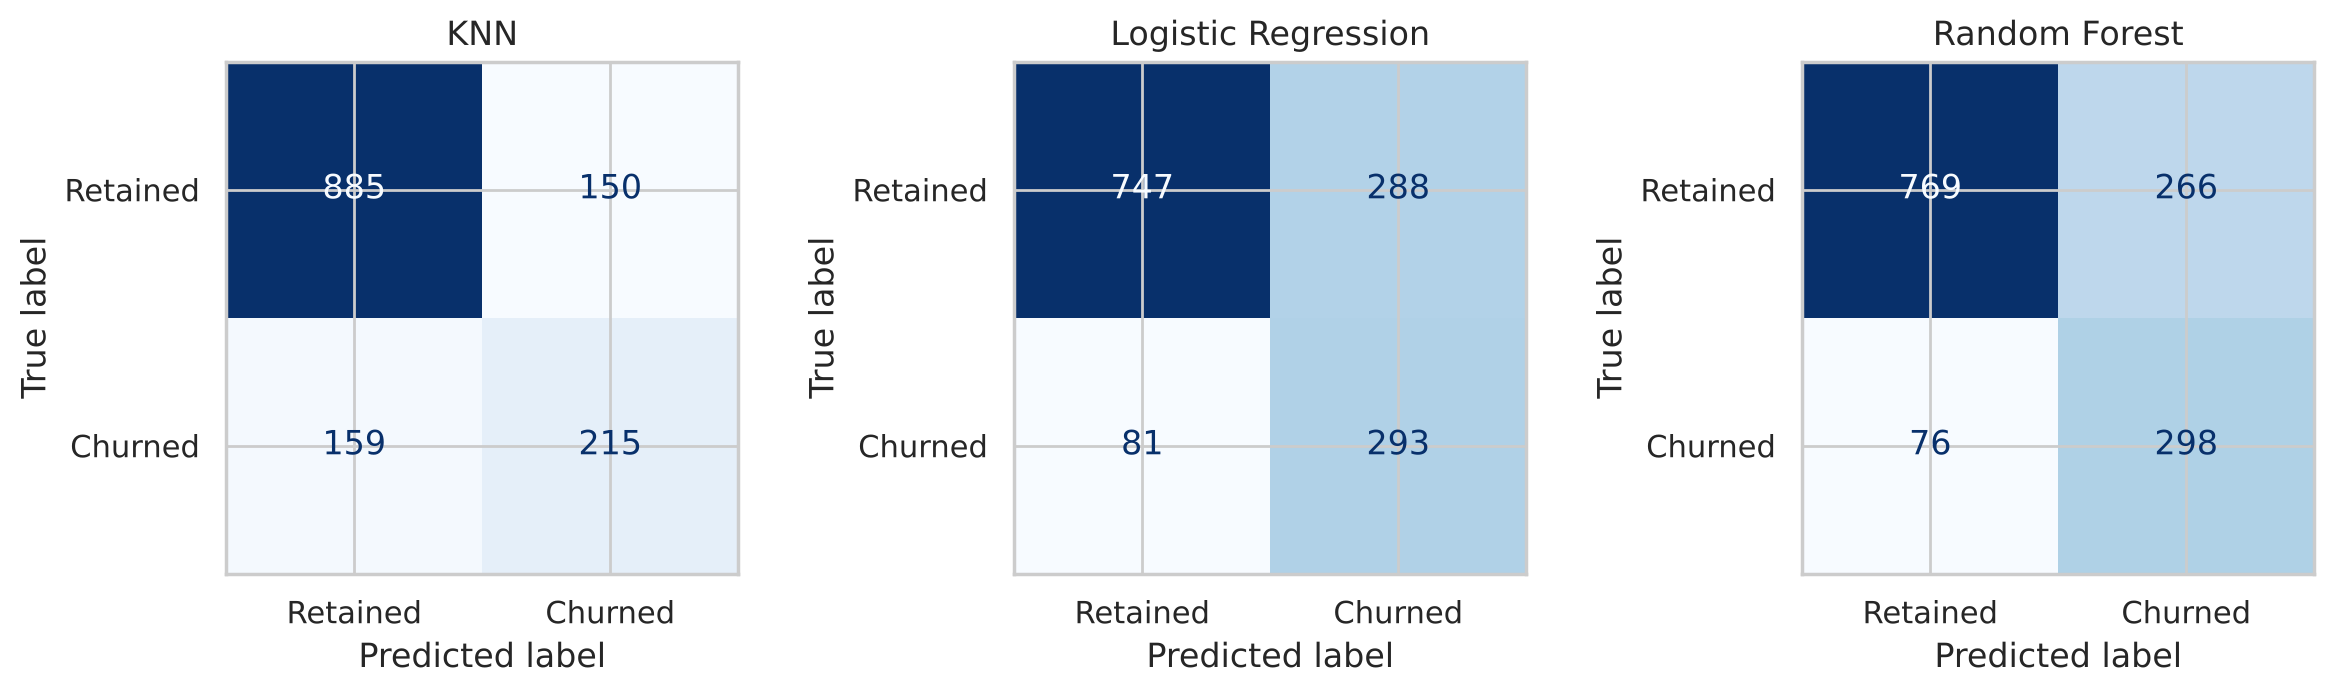

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (name, (p, _)) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["Retained", "Churned"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout(); plt.show()

Encoded feature count: 39


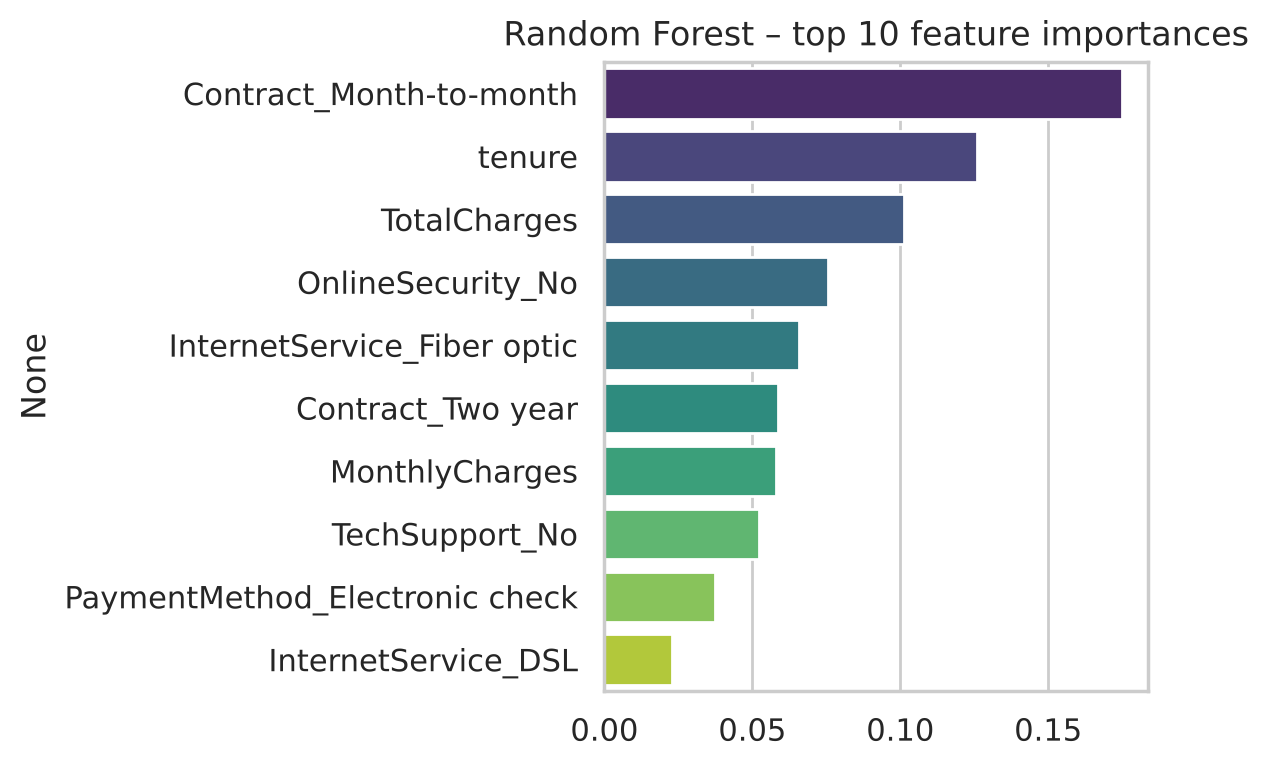

In [18]:
rf = tuned_models["Random Forest"]
names = rf.named_steps["prep"].get_feature_names_out()
print("Encoded feature count:", len(names))
imp = pd.Series(rf.named_steps["clf"].feature_importances_,
                index=[n.split("__")[1] for n in names]).sort_values(ascending=False).head(10)
fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=imp.values, y=imp.index, ax=ax, palette="viridis")
ax.set_title("Random Forest – top 10 feature importances"); plt.tight_layout(); plt.show()

In [19]:
lr = tuned_models["Logistic Regression"]
coef = pd.Series(lr.named_steps["clf"].coef_[0],
                 index=[n.split("__")[1] for n in lr.named_steps["prep"].get_feature_names_out()])
print("Strongest positive coefficients (raise churn risk):"); print(coef.sort_values(ascending=False).head(5).round(2))
print("\nStrongest negative coefficients (lower churn risk):"); print(coef.sort_values().head(5).round(2))
print("\nNote: TotalCharges and tenure are correlated (r = %.2f), so coefficients should not be read in isolation." %
      df[["tenure", "TotalCharges"]].corr().iloc[0, 1])

Strongest positive coefficients (raise churn risk):
InternetService_Fiber optic    1.28
Contract_Month-to-month        0.56
StreamingMovies_Yes            0.51
TotalCharges                   0.51
StreamingTV_Yes                0.50
dtype: float64

Strongest negative coefficients (lower churn risk):
MonthlyCharges                   -2.03
tenure                           -1.17
InternetService_DSL              -1.17
Contract_Two year                -0.90
MultipleLines_No phone service   -0.75
dtype: float64

Note: TotalCharges and tenure are correlated (r = 0.83), so coefficients should not be read in isolation.


## 7. Fairness audit (supports Task 3 – AI ethics)
`gender` was removed from the model inputs but is retained here to check for unequal behaviour. `SeniorCitizen` is also audited because it is age-related and sensitive.

In [20]:
audit = []
for name, mdl in tuned_models.items():
    pt = mdl.predict(X_test)
    for g in ["gender", "SeniorCitizen"]:
        for v in sorted(X_test[g].unique()):
            m = (X_test[g] == v).values; yt = y_test.values[m]
            tn, fp, fn, tp = confusion_matrix(yt, pt[m]).ravel()
            audit.append({"Model": name, "Attribute": g, "Group": v, "n": int(m.sum()),
                          "Actual churn rate": yt.mean(), "Predicted churn rate": pt[m].mean(),
                          "Recall (TPR)": tp / (tp + fn), "FPR": fp / (fp + tn), "Accuracy": (tp + tn) / m.sum()})
audit = pd.DataFrame(audit).round(3)
audit

,Model,Attribute,Group,n,Actual churn rate,Predicted churn rate,Recall (TPR),FPR,Accuracy
0,KNN,gender,Female,687,0.281,0.258,0.544,0.146,0.767
1,KNN,gender,Male,722,0.251,0.260,0.608,0.144,0.794
2,KNN,SeniorCitizen,No,1187,0.233,0.217,0.540,0.120,0.801
3,KNN,SeniorCitizen,Yes,222,0.441,0.482,0.673,0.331,0.671
4,Logistic Regression,gender,Female,687,0.281,0.410,0.767,0.271,0.739
5,Logistic Regression,gender,Male,722,0.251,0.414,0.801,0.285,0.737
6,Logistic Regression,SeniorCitizen,No,1187,0.233,0.360,0.728,0.248,0.746
7,Logistic Regression,SeniorCitizen,Yes,222,0.441,0.694,0.939,0.500,0.694
8,Random Forest,gender,Female,687,0.281,0.392,0.777,0.241,0.764
9,Random Forest,gender,Male,722,0.251,0.409,0.818,0.272,0.751


**Findings:** gender gaps are small. Senior citizens are flagged far more often and have a roughly 2× higher false-positive rate, so the model should only support low-stakes actions (e.g. retention offers) – never penalties such as service restrictions or price rises.

**Post-deployment plan (summary):** monitor performance and drift (e.g. PSI), run recurring fairness audits, keep humans in the loop and allow customers to contest decisions, publish a model card, and evaluate retention campaigns with a hold-out group.